In [1]:
import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

PyTorch version: 2.14.1+cpu
Device: cpu


In [2]:
DATA_DIR = Path(r"D:\Coding\thesis")

CSV_FILE = DATA_DIR / "daily_tourism_demand_forecasting_2000_2015.csv"

raw = pd.read_csv(CSV_FILE)

print("Dataset loaded successfully.")
print("Shape:", raw.shape)

display(raw.head())

Dataset loaded successfully.
Shape: (29220, 8)


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Paris,152,91.861719,34,24.279758,1.098658,Festival
1,2000-01-01,Tokyo,152,77.833310,94,13.369956,0.833709,Festival
2,2000-01-01,New York,153,88.322903,41,-2.743537,1.221999,Festival
3,2000-01-01,London,207,68.493564,83,34.688462,1.117482,Exhibition
4,2000-01-01,Berlin,107,80.990257,68,15.990986,0.899861,Exhibition


In [3]:
TIME_COL = "Date"
TARGET_COL = "Visitor_Count"
DESTINATION_COL = "Destination"

SELECTED_DESTINATION = "Paris"

data = raw.copy()

data[TIME_COL] = pd.to_datetime(
    data[TIME_COL],
    errors="raise"
)

data = data[
    data[DESTINATION_COL] == SELECTED_DESTINATION
].copy()

data = data.sort_values(
    TIME_COL
).reset_index(drop=True)

print("Selected Destination:", SELECTED_DESTINATION)
print("Number of records:", len(data))

display(data.head())

Selected Destination: Paris
Number of records: 5844


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Paris,152,91.861719,34,24.279758,1.098658,Festival
1,2000-01-02,Paris,269,98.950221,34,13.242799,1.285176,Conference
2,2000-01-03,Paris,84,96.372816,55,2.289444,1.255361,Festival
3,2000-01-04,Paris,237,81.707843,60,6.850940,0.665267,Exhibition
4,2000-01-05,Paris,86,89.184247,54,13.888597,0.619594,NaN


In [4]:
print("Missing values:")
display(data.isnull().sum())

print("Duplicate dates:", data[TIME_COL].duplicated().sum())

print("Date range:")
print(data[TIME_COL].min(), "to", data[TIME_COL].max())

print("Date frequency:")
print(data[TIME_COL].diff().value_counts().head())

Missing values:


Date                      0
Destination               0
Visitor_Count             0
Hotel_Occupancy           0
Flight_Arrivals           0
Average_Temperature       0
Economic_Index            0
Major_Event            1175
dtype: int64

Duplicate dates: 0
Date range:
2000-01-01 00:00:00 to 2015-12-31 00:00:00
Date frequency:
Date
1 days    5843
Name: count, dtype: int64


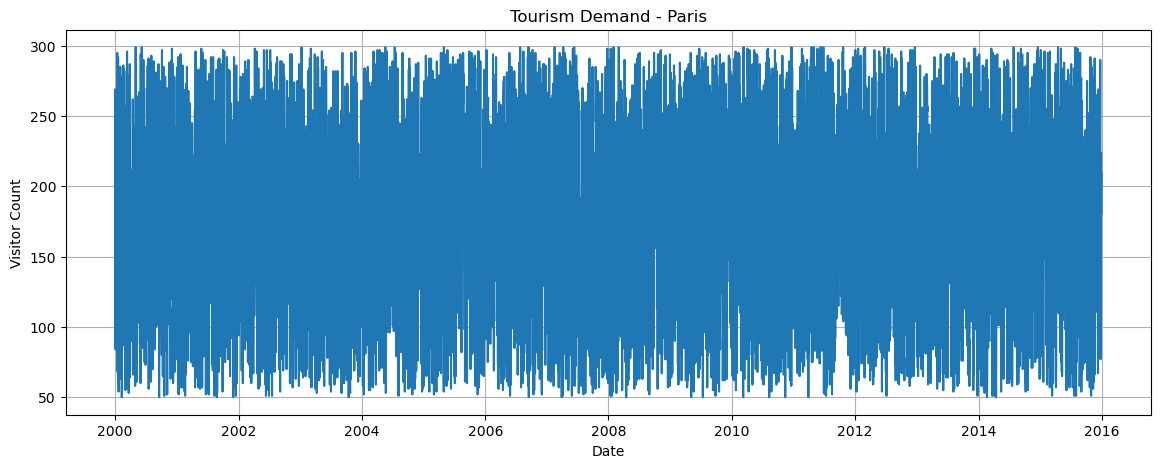

In [4]:
data = data.dropna(subset=[TARGET_COL]).copy()

values = data[TARGET_COL].values.astype(np.float32)

dates = data[TIME_COL].values

plt.figure(figsize=(14, 5))

plt.plot(data[TIME_COL], values)

plt.title(f"Tourism Demand - {SELECTED_DESTINATION}")
plt.xlabel("Date")
plt.ylabel("Visitor Count")

plt.grid(True)
plt.show()

In [5]:
LOOKBACK = 30
HORIZON = 1

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

BATCH_SIZE = 64

D_MODEL = 64
N_HEADS = 4
NUM_TRANSFORMER_LAYERS = 2

LSTM_HIDDEN = 64
LSTM_LAYERS = 1

DROPOUT = 0.1

LEARNING_RATE = 0.001
EPOCHS = 100
PATIENCE = 15

print("LOOKBACK:", LOOKBACK)
print("HORIZON:", HORIZON)
print("Device:", DEVICE)

LOOKBACK: 30
HORIZON: 1
Device: cpu


In [6]:
n = len(values)

train_end = int(n * TRAIN_FRAC)
val_end = int(n * (TRAIN_FRAC + VAL_FRAC))

print("Total samples:", n)

print("Train:", 0, "to", train_end - 1)
print("Validation:", train_end, "to", val_end - 1)
print("Test:", val_end, "to", n - 1)

Total samples: 5844
Train: 0 to 4089
Validation: 4090 to 4966
Test: 4967 to 5843


In [7]:
scaler = StandardScaler()

scaler.fit(
    values[:train_end].reshape(-1, 1)
)

scaled_values = scaler.transform(
    values.reshape(-1, 1)
).flatten()

print("Scaling completed.")

Scaling completed.


In [8]:
def create_windows(
    values,
    lookback,
    horizon,
    start_target,
    end_target
):

    X = []
    y = []
    target_indices = []

    for target_idx in range(
        start_target,
        end_target - horizon + 1
    ):

        x_start = target_idx - lookback

        if x_start < 0:
            continue

        x = values[x_start:target_idx]

        target = values[
            target_idx:target_idx + horizon
        ]

        X.append(x)
        y.append(target)
        target_indices.append(target_idx)

    X = np.asarray(
        X,
        dtype=np.float32
    ).reshape(-1, lookback, 1)

    y = np.asarray(
        y,
        dtype=np.float32
    ).reshape(-1, horizon)

    target_indices = np.asarray(target_indices)

    return X, y, target_indices

In [9]:
X_train, y_train, idx_train = create_windows(
    scaled_values,
    LOOKBACK,
    HORIZON,
    LOOKBACK,
    train_end
)

X_val, y_val, idx_val = create_windows(
    scaled_values,
    LOOKBACK,
    HORIZON,
    train_end,
    val_end
)

X_test, y_test, idx_test = create_windows(
    scaled_values,
    LOOKBACK,
    HORIZON,
    val_end,
    n
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (4060, 30, 1) (4060, 1)
Validation: (877, 30, 1) (877, 1)
Testing: (877, 30, 1) (877, 1)


In [10]:
class TourismDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.y[index]


train_dataset = TourismDataset(X_train, y_train)
val_dataset = TourismDataset(X_val, y_val)
test_dataset = TourismDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [11]:
class TransformerLSTM(nn.Module):

    def __init__(
        self,
        input_size=1,
        d_model=64,
        n_heads=4,
        num_transformer_layers=2,
        lstm_hidden=64,
        lstm_layers=1,
        dropout=0.1,
        max_len=30,
        horizon=1
    ):

        super().__init__()

        # Project input into Transformer dimension
        self.input_projection = nn.Linear(
            input_size,
            d_model
        )

        # Learnable positional encoding
        self.positional_encoding = nn.Parameter(
            torch.zeros(1, max_len, d_model)
        )

        nn.init.trunc_normal_(
            self.positional_encoding,
            std=0.02
        )

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 2,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_transformer_layers
        )

        # LSTM
        self.lstm = nn.LSTM(
            input_size=d_model,
            hidden_size=lstm_hidden,
            num_layers=lstm_layers,
            batch_first=True,
            dropout=dropout if lstm_layers > 1 else 0
        )

        # Output layer
        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            lstm_hidden,
            horizon
        )

    def forward(self, x):

        # x: [batch, sequence, features]

        x = self.input_projection(x)

        x = x + self.positional_encoding[
            :, :x.size(1), :
        ]

        x = self.transformer(x)

        x, _ = self.lstm(x)

        # Use the final time step
        x = x[:, -1, :]

        x = self.dropout(x)

        output = self.fc(x)

        return output

In [12]:
model = TransformerLSTM(
    input_size=1,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    num_transformer_layers=NUM_TRANSFORMER_LAYERS,
    lstm_hidden=LSTM_HIDDEN,
    lstm_layers=LSTM_LAYERS,
    dropout=DROPOUT,
    max_len=LOOKBACK,
    horizon=HORIZON
).to(DEVICE)

print(model)

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable Parameters:", total_params)

TransformerLSTM(
  (input_projection): Linear(in_features=1, out_features=64, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

Trainable Parameters: 102337


In [13]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

print("Loss and optimizer initialized.")

Loss and optimizer initialized.


In [14]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * len(X_batch)

    return total_loss / len(loader.dataset)


def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            total_loss += loss.item() * len(X_batch)

    return total_loss / len(loader.dataset)

In [15]:
best_val_loss = float("inf")
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": []
}

BEST_MODEL_PATH = Path(
    f"best_transformer_lstm_{SELECTED_DESTINATION}.pth"
)

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        patience_counter = 0

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

    else:

        patience_counter += 1

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.6f} "
            f"Val Loss: {val_loss:.6f}"
        )

    if patience_counter >= PATIENCE:

        print("Early stopping triggered.")

        break

print("\nTraining completed.")
print("Best Validation Loss:", best_val_loss)

Epoch [5/100] Train Loss: 1.002579 Val Loss: 0.980888
Epoch [10/100] Train Loss: 0.999931 Val Loss: 0.975502
Epoch [15/100] Train Loss: 0.999218 Val Loss: 0.977504
Early stopping triggered.

Training completed.
Best Validation Loss: 0.9709977126311821


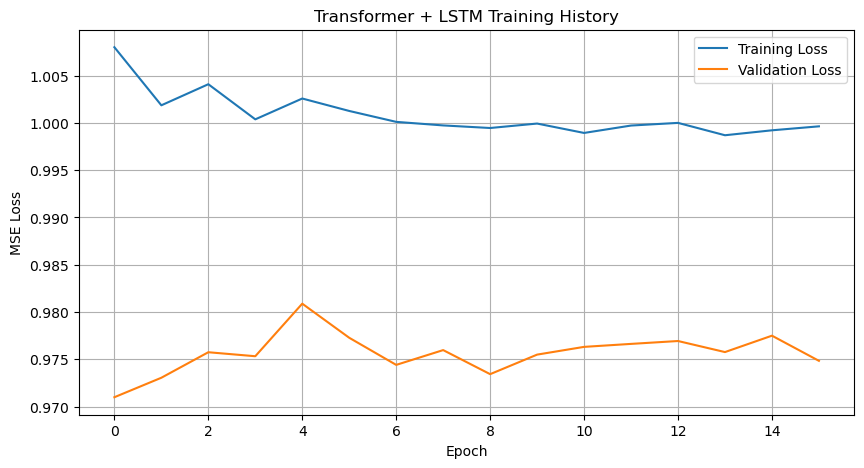

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.title("Transformer + LSTM Training History")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()

In [17]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=True
    )
)

model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


In [18]:
predictions = []

model.eval()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(DEVICE)

        pred = model(X_batch)

        predictions.append(
            pred.cpu().numpy()
        )

pred_scaled = np.concatenate(
    predictions,
    axis=0
).reshape(-1)

pred_original = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).flatten()

y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

print("Prediction completed.")
print("Number of predictions:", len(pred_original))

Prediction completed.
Number of predictions: 877


In [19]:
def calculate_smape(y_true, y_pred):

    denominator = (
        np.abs(y_true) + np.abs(y_pred)
    ) / 2

    denominator = np.maximum(
        denominator,
        1e-8
    )

    return np.mean(
        np.abs(y_true - y_pred) / denominator
    ) * 100


mae = mean_absolute_error(
    y_test_original,
    pred_original
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_original,
        pred_original
    )
)

smape_value = calculate_smape(
    y_test_original,
    pred_original
)

print("Transformer + LSTM Evaluation")
print("------------------------------")
print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"sMAPE: {smape_value:.2f}%")

Transformer + LSTM Evaluation
------------------------------
MAE:   63.6696
RMSE:  73.1407
sMAPE: 38.97%


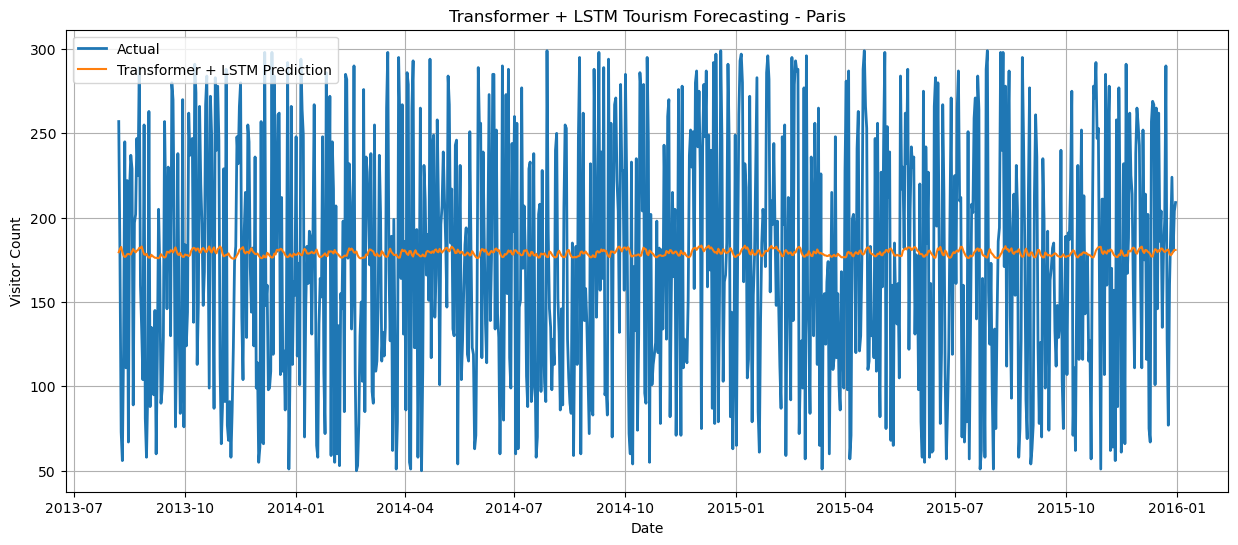

In [20]:
test_dates = data.iloc[idx_test][TIME_COL].values

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    y_test_original,
    label="Actual",
    linewidth=2
)

plt.plot(
    test_dates,
    pred_original,
    label="Transformer + LSTM Prediction",
    linewidth=1.5
)

plt.title(
    f"Transformer + LSTM Tourism Forecasting - {SELECTED_DESTINATION}"
)

plt.xlabel("Date")
plt.ylabel("Visitor Count")

plt.legend()
plt.grid(True)
plt.show()

In [21]:
OUTPUT_DIR = Path("transformer_lstm_results")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save model
torch.save(
    model.state_dict(),
    OUTPUT_DIR / f"transformer_lstm_{SELECTED_DESTINATION}.pth"
)

# Save scaler
joblib.dump(
    scaler,
    OUTPUT_DIR / f"scaler_{SELECTED_DESTINATION}.joblib"
)

# Save predictions
prediction_df = pd.DataFrame({
    "Date": test_dates,
    "Actual": y_test_original,
    "Predicted": pred_original
})

prediction_df.to_csv(
    OUTPUT_DIR / f"transformer_lstm_predictions_{SELECTED_DESTINATION}.csv",
    index=False
)

# Save metrics
metrics_df = pd.DataFrame({
    "Model": ["Transformer + LSTM"],
    "Destination": [SELECTED_DESTINATION],
    "MAE": [mae],
    "RMSE": [rmse],
    "sMAPE": [smape_value]
})

metrics_df.to_csv(
    OUTPUT_DIR / f"transformer_lstm_metrics_{SELECTED_DESTINATION}.csv",
    index=False
)

print("Model and results saved successfully.")
print("Output directory:", OUTPUT_DIR.resolve())

Model and results saved successfully.
Output directory: D:\Coding\thesis\transformer_lstm_results


# Global Transformer + LSTM

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import joblib

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [4]:
FILE_PATH = r"D:\Coding\thesis\daily_tourism_demand_forecasting_2000_2015.csv"

df = pd.read_csv(FILE_PATH)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (29220, 8)
         Date Destination  Visitor_Count  Hotel_Occupancy  Flight_Arrivals  \
0  2000-01-01       Paris            152        91.861719               34   
1  2000-01-01       Tokyo            152        77.833310               94   
2  2000-01-01    New York            153        88.322903               41   
3  2000-01-01      London            207        68.493564               83   
4  2000-01-01      Berlin            107        80.990257               68   

   Average_Temperature  Economic_Index Major_Event  
0            24.279758        1.098658    Festival  
1            13.369956        0.833709    Festival  
2            -2.743537        1.221999    Festival  
3            34.688462        1.117482  Exhibition  
4            15.990986        0.899861  Exhibition  


In [5]:
DATE_COL = "Date"
CITY_COL = "Destination"
TARGET_COL = "Visitor_Count"

CITIES = [
    "Paris",
    "Tokyo",
    "New York",
    "London",
    "Berlin"
]

LOOKBACK = 30
HORIZON = 1

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 0.001

PATIENCE = 15

RESULT_DIR = "global_transformer_lstm_results"
os.makedirs(RESULT_DIR, exist_ok=True)

In [6]:
df[DATE_COL] = pd.to_datetime(df[DATE_COL])

df = df[
    df[CITY_COL].isin(CITIES)
].copy()

df = df.sort_values(
    [CITY_COL, DATE_COL]
).reset_index(drop=True)

df[TARGET_COL] = pd.to_numeric(
    df[TARGET_COL],
    errors="coerce"
)

print("Dataset shape:", df.shape)

print("\nCities:")
print(df[CITY_COL].value_counts())

print("\nMissing values:")
print(df[[DATE_COL, CITY_COL, TARGET_COL]].isnull().sum())

print("\nDuplicate city-date records:",
      df.duplicated([CITY_COL, DATE_COL]).sum())

Dataset shape: (29220, 8)

Cities:
Destination
Berlin      5844
London      5844
New York    5844
Paris       5844
Tokyo       5844
Name: count, dtype: int64

Missing values:
Date             0
Destination      0
Visitor_Count    0
dtype: int64

Duplicate city-date records: 0


In [7]:
for city in CITIES:

    city_df = df[df[CITY_COL] == city].sort_values(DATE_COL)

    date_diff = city_df[DATE_COL].diff().dropna()

    missing_days = (date_diff.dt.days != 1).sum()

    print(
        f"{city}: {len(city_df)} records | "
        f"Non-daily gaps: {missing_days}"
    )

Paris: 5844 records | Non-daily gaps: 0
Tokyo: 5844 records | Non-daily gaps: 0
New York: 5844 records | Non-daily gaps: 0
London: 5844 records | Non-daily gaps: 0
Berlin: 5844 records | Non-daily gaps: 0


In [8]:
unique_dates = np.sort(
    df[DATE_COL].dropna().unique()
)

n_dates = len(unique_dates)

train_end = int(n_dates * TRAIN_FRAC)

val_end = int(
    n_dates * (TRAIN_FRAC + VAL_FRAC)
)

train_cutoff = unique_dates[train_end]
val_cutoff = unique_dates[val_end]

train_df = df[df[DATE_COL] < train_cutoff].copy()

val_df = df[
    (df[DATE_COL] >= train_cutoff) &
    (df[DATE_COL] < val_cutoff)
].copy()

test_df = df[df[DATE_COL] >= val_cutoff].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain cutoff:", train_cutoff)
print("Validation cutoff:", val_cutoff)

Train: (20450, 8)
Validation: (4385, 8)
Test: (4385, 8)

Train cutoff: 2011-03-14T00:00:00.000000000
Validation cutoff: 2013-08-07T00:00:00.000000000


In [9]:
scaler = StandardScaler()

scaler.fit(
    train_df[[TARGET_COL]]
)

df["Visitor_Count_Scaled"] = scaler.transform(
    df[[TARGET_COL]]
)

print("Scaler mean:", scaler.mean_)
print("Scaler scale:", scaler.scale_)

Scaler mean: [174.58889976]
Scaler scale: [72.17356589]


In [10]:
city_dummies = pd.get_dummies(
    df[CITY_COL],
    prefix="City",
    dtype=float
)

CITY_FEATURES = [
    f"City_{city}" for city in CITIES
]

city_dummies = city_dummies.reindex(
    columns=CITY_FEATURES,
    fill_value=0
)

df = pd.concat(
    [df, city_dummies],
    axis=1
)

print("City features:")
print(CITY_FEATURES)

print(df[
    [CITY_COL] + CITY_FEATURES
].head())

City features:
['City_Paris', 'City_Tokyo', 'City_New York', 'City_London', 'City_Berlin']
  Destination  City_Paris  City_Tokyo  City_New York  City_London  City_Berlin
0      Berlin         0.0         0.0            0.0          0.0          1.0
1      Berlin         0.0         0.0            0.0          0.0          1.0
2      Berlin         0.0         0.0            0.0          0.0          1.0
3      Berlin         0.0         0.0            0.0          0.0          1.0
4      Berlin         0.0         0.0            0.0          0.0          1.0


In [11]:
def create_sequences(data, lookback, horizon):

    X = []
    y = []
    dates = []
    cities = []

    feature_columns = [
        "Visitor_Count_Scaled"
    ] + CITY_FEATURES

    for city in CITIES:

        city_df = data[
            data[CITY_COL] == city
        ].sort_values(DATE_COL).reset_index(drop=True)

        values = city_df[
            feature_columns
        ].values.astype(np.float32)

        target_values = city_df[
            "Visitor_Count_Scaled"
        ].values.astype(np.float32)

        city_dates = city_df[DATE_COL].values

        for target_idx in range(
            lookback,
            len(city_df) - horizon + 1
        ):

            x_start = target_idx - lookback
            x_end = target_idx

            target_end = target_idx + horizon

            window_dates = city_dates[
                x_start:target_end
            ]

            # Check daily continuity
            date_diffs = np.diff(
                window_dates.astype("datetime64[D]")
            ).astype(int)

            if not np.all(date_diffs == 1):
                continue

            sequence = values[x_start:x_end]

            target = target_values[
                target_end - 1
            ]

            X.append(sequence)
            y.append(target)

            dates.append(
                city_dates[target_end - 1]
            )

            cities.append(city)

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(dates),
        np.array(cities)
    )

In [12]:
train_data = df[
    df[DATE_COL] < train_cutoff
].copy()

X_train, y_train, train_dates, train_cities = create_sequences(
    train_data,
    LOOKBACK,
    HORIZON
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (20300, 30, 6)
y_train: (20300,)


In [13]:
val_data = df[
    df[DATE_COL] < val_cutoff
].copy()

X_val_all, y_val_all, val_dates_all, val_cities_all = create_sequences(
    val_data,
    LOOKBACK,
    HORIZON
)

val_mask = val_dates_all >= train_cutoff

X_val = X_val_all[val_mask]
y_val = y_val_all[val_mask]

val_dates = val_dates_all[val_mask]
val_cities = val_cities_all[val_mask]

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_val: (4385, 30, 6)
y_val: (4385,)


In [14]:
test_data = df.copy()

X_test_all, y_test_all, test_dates_all, test_cities_all = create_sequences(
    test_data,
    LOOKBACK,
    HORIZON
)

test_mask = test_dates_all >= val_cutoff

X_test = X_test_all[test_mask]
y_test = y_test_all[test_mask]

test_dates = test_dates_all[test_mask]
test_cities = test_cities_all[test_mask]

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (4385, 30, 6)
y_test: (4385,)


In [15]:
class TourismDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        ).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        return self.X[idx], self.y[idx]

In [16]:
train_dataset = TourismDataset(
    X_train,
    y_train
)

val_dataset = TourismDataset(
    X_val,
    y_val
)

test_dataset = TourismDataset(
    X_test,
    y_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 318
Validation batches: 69
Test batches: 69


In [17]:
class PositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len=500):

        super().__init__()

        position = torch.arange(
            max_len
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-np.log(10000.0) / d_model)
        )

        pe = torch.zeros(
            max_len,
            d_model
        )

        pe[:, 0::2] = torch.sin(
            position * div_term
        )

        pe[:, 1::2] = torch.cos(
            position * div_term
        )

        pe = pe.unsqueeze(0)

        self.register_buffer("pe", pe)

    def forward(self, x):

        return x + self.pe[:, :x.size(1), :]

In [18]:
class TransformerLSTM(nn.Module):

    def __init__(
        self,
        input_size=6,
        d_model=64,
        nhead=4,
        num_transformer_layers=2,
        hidden_size=64,
        num_lstm_layers=2,
        dropout=0.1
    ):

        super().__init__()

        self.input_projection = nn.Linear(
            input_size,
            d_model
        )

        self.positional_encoding = PositionalEncoding(
            d_model
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_transformer_layers
        )

        self.lstm = nn.LSTM(
            input_size=d_model,
            hidden_size=hidden_size,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=dropout if num_lstm_layers > 1 else 0
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        # Project input features
        x = self.input_projection(x)

        # Add positional information
        x = self.positional_encoding(x)

        # Transformer Encoder
        x = self.transformer(x)

        # LSTM
        output, (hidden, cell) = self.lstm(x)

        # Use last time step
        x = output[:, -1, :]

        # Prediction
        x = self.fc(x)

        return x

In [19]:
INPUT_SIZE = 1 + len(CITY_FEATURES)

model = TransformerLSTM(
    input_size=INPUT_SIZE,
    d_model=64,
    nhead=4,
    num_transformer_layers=2,
    hidden_size=64,
    num_lstm_layers=2,
    dropout=0.1
).to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", total_params)

TransformerLSTM(
  (input_projection): Linear(in_features=6, out_features=64, bias=True)
  (positional_encoding): PositionalEncoding()
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (lstm): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bia

In [20]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

In [21]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * len(X_batch)

    return total_loss / len(loader.dataset)

In [22]:
def validate_one_epoch(model, loader, criterion):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            total_loss += loss.item() * len(X_batch)

    return total_loss / len(loader.dataset)

In [23]:
best_val_loss = float("inf")
patience_counter = 0

train_losses = []
val_losses = []

best_model_path = os.path.join(
    RESULT_DIR,
    "best_transformer_lstm.pth"
)

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            best_model_path
        )

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print("Early stopping triggered.")
        break

print("\nBest Validation Loss:", best_val_loss)

Epoch [1/100] Train Loss: 1.001162 | Val Loss: 0.981644 | LR: 0.001000
Epoch [2/100] Train Loss: 1.000790 | Val Loss: 0.981156 | LR: 0.001000
Epoch [3/100] Train Loss: 1.000671 | Val Loss: 0.979912 | LR: 0.001000
Epoch [4/100] Train Loss: 1.000687 | Val Loss: 0.980053 | LR: 0.001000
Epoch [5/100] Train Loss: 1.000675 | Val Loss: 0.981485 | LR: 0.001000
Epoch [6/100] Train Loss: 1.000721 | Val Loss: 0.980970 | LR: 0.001000
Epoch [7/100] Train Loss: 1.000607 | Val Loss: 0.980236 | LR: 0.001000
Epoch [8/100] Train Loss: 1.000493 | Val Loss: 0.980775 | LR: 0.001000
Epoch [9/100] Train Loss: 1.000536 | Val Loss: 0.980516 | LR: 0.000500
Epoch [10/100] Train Loss: 1.000406 | Val Loss: 0.980510 | LR: 0.000500
Epoch [11/100] Train Loss: 1.000533 | Val Loss: 0.980486 | LR: 0.000500
Epoch [12/100] Train Loss: 1.000321 | Val Loss: 0.979918 | LR: 0.000500
Epoch [13/100] Train Loss: 1.000554 | Val Loss: 0.980059 | LR: 0.000500
Epoch [14/100] Train Loss: 1.000570 | Val Loss: 0.980514 | LR: 0.000500
E

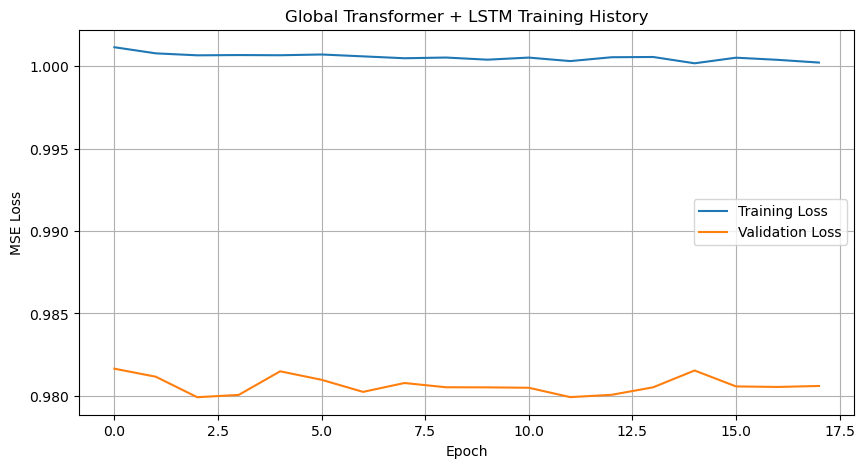

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Global Transformer + LSTM Training History")

plt.legend()
plt.grid(True)

plt.show()

In [25]:
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


In [26]:
predictions = []
actuals = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        pred = model(X_batch)

        predictions.extend(
            pred.cpu().numpy().flatten()
        )

        actuals.extend(
            y_batch.numpy().flatten()
        )

predictions = np.array(predictions).reshape(-1, 1)
actuals = np.array(actuals).reshape(-1, 1)

# Convert back to original scale
predictions_original = scaler.inverse_transform(
    predictions
).flatten()

actuals_original = scaler.inverse_transform(
    actuals
).flatten()

print("Prediction samples:", len(predictions_original))

Prediction samples: 4385


In [27]:
def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    nonzero_mask = actual != 0

    if nonzero_mask.sum() > 0:

        smape = np.mean(
            2 * np.abs(
                predicted[nonzero_mask] -
                actual[nonzero_mask]
            ) /
            (
                np.abs(predicted[nonzero_mask]) +
                np.abs(actual[nonzero_mask]) +
                1e-8
            )
        ) * 100

    else:
        smape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE": smape
    }


overall_metrics = calculate_metrics(
    actuals_original,
    predictions_original
)

print("Overall Test Metrics")

for metric, value in overall_metrics.items():

    print(f"{metric}: {value:.4f}")

Overall Test Metrics
MAE: 63.0591
RMSE: 72.7910
sMAPE: 38.7336


In [28]:
prediction_df = pd.DataFrame({
    "Date": pd.to_datetime(test_dates),
    "Destination": test_cities,
    "Actual": actuals_original,
    "Predicted": predictions_original
})

prediction_df = prediction_df.sort_values(
    ["Destination", "Date"]
).reset_index(drop=True)

print(prediction_df.head(10))

        Date Destination      Actual   Predicted
0 2013-08-07      Berlin  101.999992  176.650772
1 2013-08-08      Berlin  267.000000  176.650864
2 2013-08-09      Berlin  249.000000  176.651352
3 2013-08-10      Berlin  197.000000  176.650375
4 2013-08-11      Berlin   97.000000  176.650009
5 2013-08-12      Berlin  288.000000  176.650360
6 2013-08-13      Berlin  126.000000  176.651154
7 2013-08-14      Berlin  176.000000  176.650528
8 2013-08-15      Berlin   77.000000  176.651123
9 2013-08-16      Berlin   65.000000  176.651062


In [29]:
city_results = []

for city in CITIES:

    city_data = prediction_df[
        prediction_df["Destination"] == city
    ]

    if len(city_data) == 0:
        continue

    metrics = calculate_metrics(
        city_data["Actual"].values,
        city_data["Predicted"].values
    )

    city_results.append({
        "City": city,
        "Samples": len(city_data),
        **metrics
    })

city_metrics_df = pd.DataFrame(city_results)

print(city_metrics_df)

       City  Samples        MAE       RMSE      sMAPE
0     Paris      877  63.532772  72.991244  38.939266
1     Tokyo      877  64.300262  73.986597  39.653484
2  New York      877  61.491013  71.583707  38.205372
3    London      877  62.044006  71.664893  37.878250
4    Berlin      877  63.927254  73.694096  38.991589


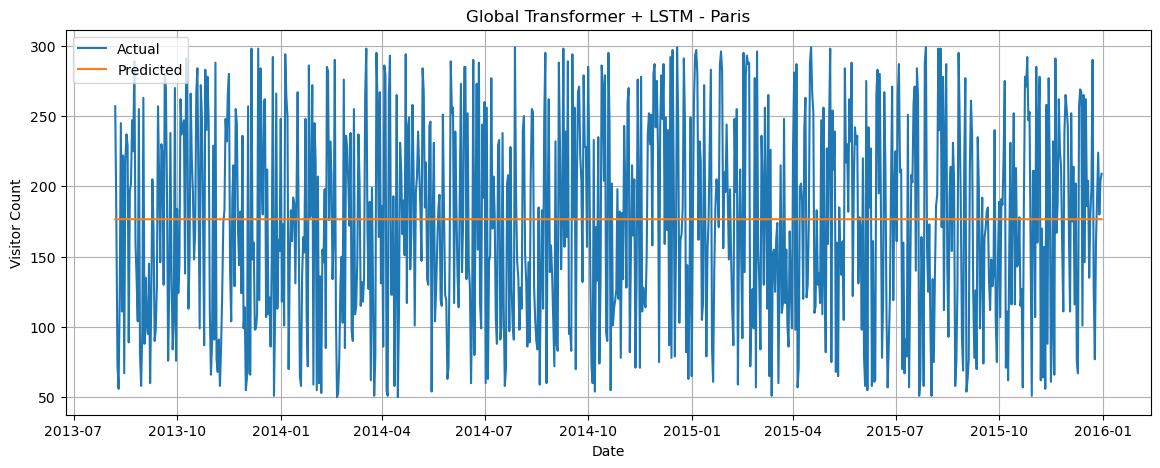

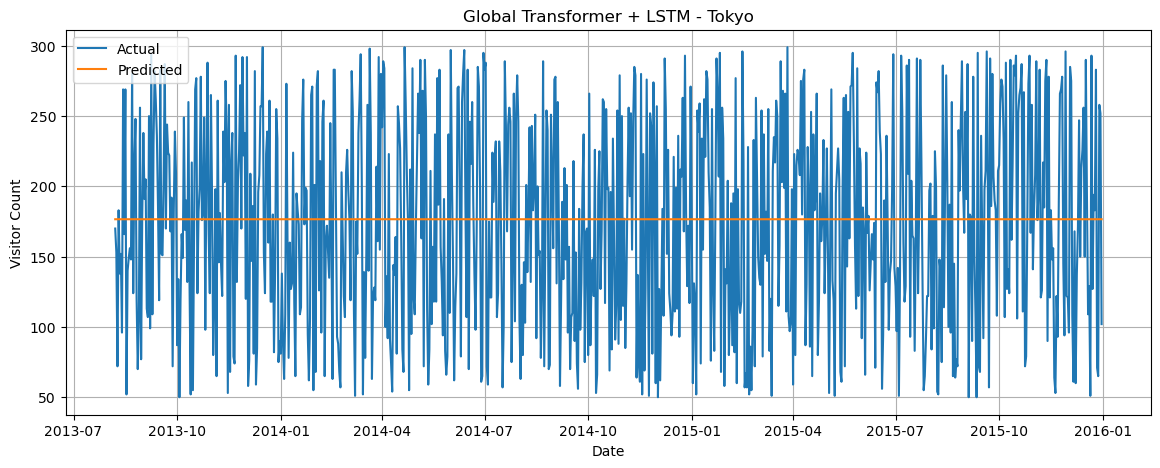

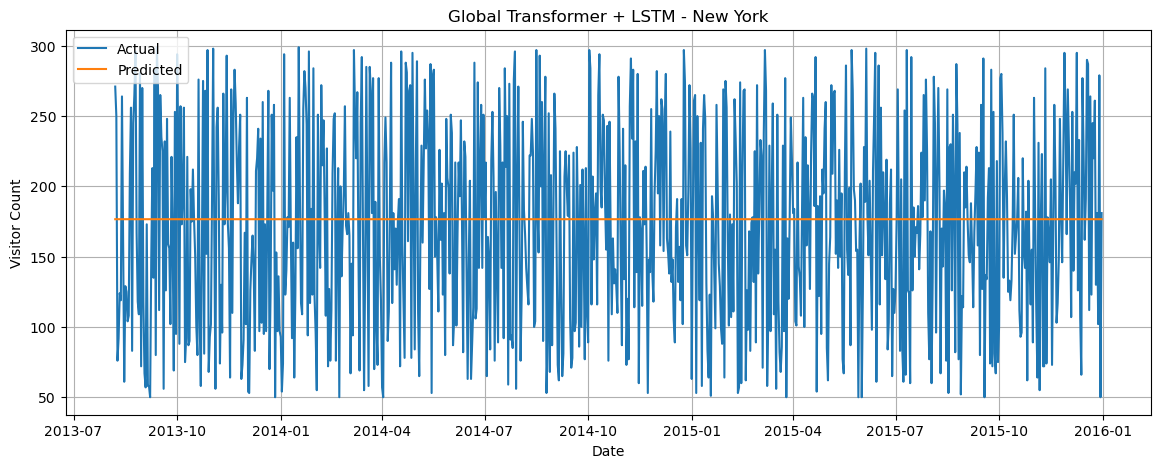

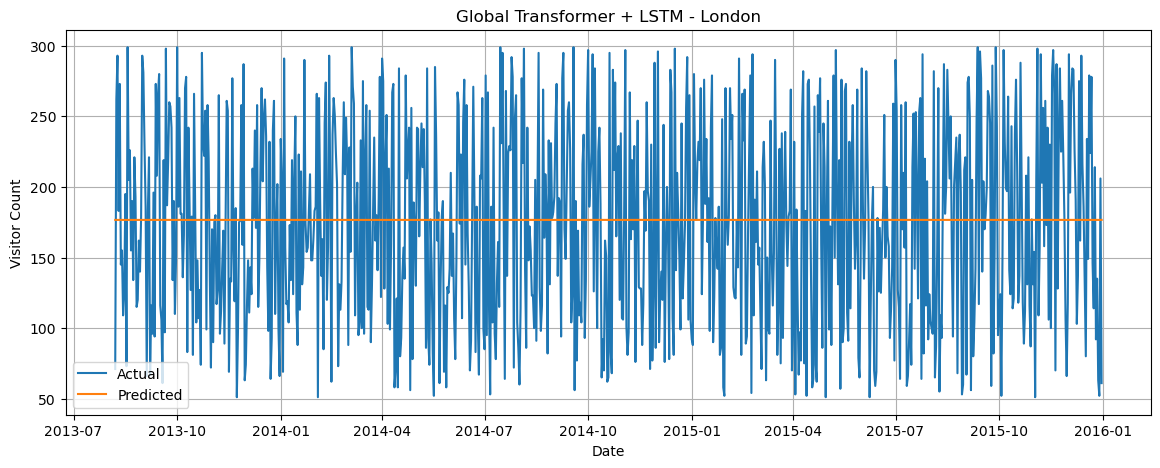

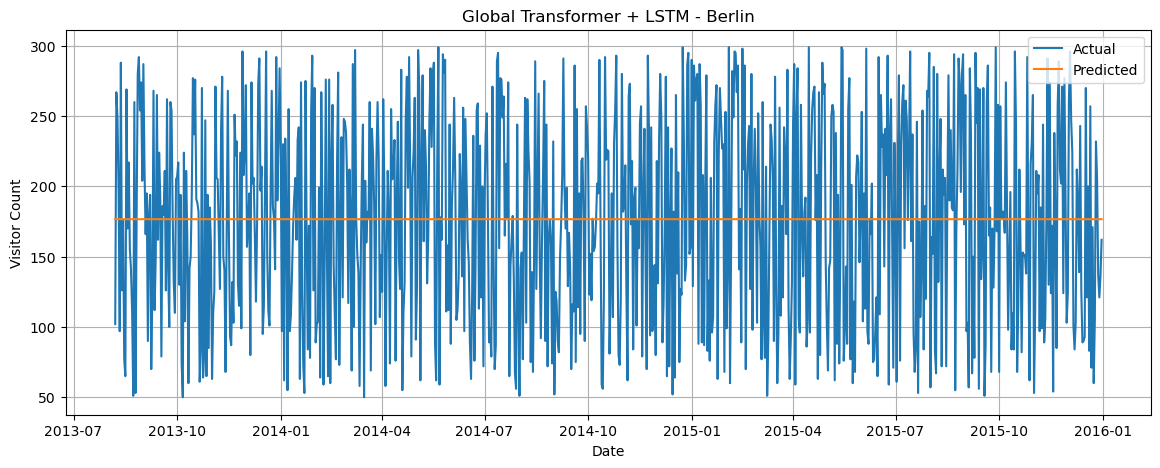

In [30]:
for city in CITIES:

    city_data = prediction_df[
        prediction_df["Destination"] == city
    ].sort_values("Date")

    if len(city_data) == 0:
        continue

    plt.figure(figsize=(14, 5))

    plt.plot(
        city_data["Date"],
        city_data["Actual"],
        label="Actual"
    )

    plt.plot(
        city_data["Date"],
        city_data["Predicted"],
        label="Predicted"
    )

    plt.title(
        f"Global Transformer + LSTM - {city}"
    )

    plt.xlabel("Date")
    plt.ylabel("Visitor Count")

    plt.legend()
    plt.grid(True)

    plt.show()

In [31]:
# Save model
torch.save(
    model.state_dict(),
    os.path.join(
        RESULT_DIR,
        "global_transformer_lstm_final.pth"
    )
)

# Save scaler
joblib.dump(
    scaler,
    os.path.join(
        RESULT_DIR,
        "global_transformer_lstm_scaler.pkl"
    )
)

# Save predictions
prediction_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "predictions.csv"
    ),
    index=False
)

# Save metrics
city_metrics_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "city_metrics.csv"
    ),
    index=False
)

pd.DataFrame([overall_metrics]).to_csv(
    os.path.join(
        RESULT_DIR,
        "overall_metrics.csv"
    ),
    index=False
)

print("All results saved successfully.")

All results saved successfully.
